In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
data = pd.read_csv('/content/classification_df.csv')

In [3]:
data.head()

,userid,rank-type,contest1,contest2,contest3,contest4,contest5,contest6,contest7,contest8,contest9,contest10
0,3143927301,Candidate Master,2078,2055,2115,2047.0,2024.0,2010.0,1953.0,1936.0,2042.0,2045.0
1,1876577621,Master,2194,2114,2152,2179.0,2211.0,2154.0,2170.0,2141.0,2157.0,2209.0
2,6397741793,Master,2120,2206,2147,2234.0,2294.0,2090.0,2089.0,2072.0,2085.0,2114.0
3,3090123616,Master,2224,2222,2166,2116.0,2029.0,2113.0,2104.0,2096.0,2115.0,2163.0
4,9564162806,Master,2128,2120,2072,2018.0,1963.0,2039.0,1932.0,1963.0,1960.0,1886.0


In [4]:
data.tail()

,userid,rank-type,contest1,contest2,contest3,contest4,contest5,contest6,contest7,contest8,contest9,contest10
1418,9480350921,Candidate Master,2000,1951,1900,1927.0,1820.0,1787.0,1721.0,1686.0,1681.0,1592.0
1419,7473555183,Candidate Master,1977,1910,1974,1823.0,1796.0,1790.0,1829.0,1717.0,1676.0,1716.0
1420,7812437094,Candidate Master,2066,2098,1888,1788.0,1689.0,1386.0,1111.0,679.0,NaN,NaN
1421,7119479728,Master,2157,2118,1818,1684.0,1387.0,787.0,NaN,NaN,NaN,NaN
1422,1504914733,Master,2243,2191,2052,1936.0,1622.0,1297.0,693.0,NaN,NaN,NaN


In [6]:
data.shape

(1423, 12)

In [7]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1423 entries, 0 to 1422
Data columns (total 12 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   userid     1423 non-null   int64  
 1   rank-type  1423 non-null   object 
 2   contest1   1423 non-null   int64  
 3   contest2   1423 non-null   int64  
 4   contest3   1423 non-null   int64  
 5   contest4   1422 non-null   float64
 6   contest5   1404 non-null   float64
 7   contest6   1374 non-null   float64
 8   contest7   1343 non-null   float64
 9   contest8   1303 non-null   float64
 10  contest9   1279 non-null   float64
 11  contest10  1252 non-null   float64
dtypes: float64(7), int64(4), object(1)
memory usage: 133.5+ KB


In [8]:
data.describe()

,userid,contest1,contest2,contest3,contest4,contest5,contest6,contest7,contest8,contest9,contest10
count,1.423000e+03,1423.000000,1423.000000,1423.000000,1422.000000,1404.000000,1374.000000,1343.000000,1303.000000,1279.000000,1252.000000
mean,5.544960e+09,2225.569220,2182.663387,2144.553760,2096.829114,2062.668803,2044.155022,2032.603127,2032.438987,2018.510555,2006.584665
std,2.556707e+09,228.588617,247.831336,277.342857,324.225868,358.430332,375.658912,388.340663,374.310185,385.680233,397.971750
min,1.002901e+09,1029.000000,1001.000000,838.000000,683.000000,570.000000,427.000000,439.000000,388.000000,453.000000,354.000000
25%,3.385677e+09,2077.000000,2022.500000,1984.000000,1940.250000,1913.750000,1894.250000,1884.500000,1877.500000,1855.000000,1843.750000
50%,5.568463e+09,2155.000000,2121.000000,2103.000000,2080.000000,2069.500000,2045.500000,2044.000000,2041.000000,2033.000000,2014.000000
75%,7.764162e+09,2314.000000,2288.000000,2278.500000,2248.000000,2246.250000,2231.750000,2221.500000,2213.000000,2201.500000,2205.250000
max,9.998497e+09,3572.000000,3697.000000,3569.000000,3487.000000,3644.000000,3833.000000,3724.000000,3727.000000,3783.000000,3813.000000


In [9]:
data.min(numeric_only=True)

,0
userid,1.002901e+09
contest1,1.029000e+03
contest2,1.001000e+03
contest3,8.380000e+02
contest4,6.830000e+02
contest5,5.700000e+02
contest6,4.270000e+02
contest7,4.390000e+02
contest8,3.880000e+02
contest9,4.530000e+02


In [10]:
data.max(numeric_only=False)

,0
userid,9998496758
rank-type,Pupil
contest1,3572
contest2,3697
contest3,3569
contest4,3487.0
contest5,3644.0
contest6,3833.0
contest7,3724.0
contest8,3727.0


In [11]:
data['contest10'].unique()

array([2045., 2209., 2114., 2163., 1886., 1769., 1454., 2208., 1973.,
       1507., 2092., 1833., 2002., 1851., 2175., 2201., 2544., 2049.,
       2215., 1289., 1619., 2560., 2066., 2704., 2118., 2251.,  656.,
       2013., 2077., 2438., 1979., 1674., 2199., 2037., 2053., 2014.,
       2304., 1877., 2282., 1704., 2181., 2141., 2079., 2150., 2059.,
       1909., 1689., 1678., 1971., 2074., 3016., 2204.,   nan, 1881.,
       2338., 1959., 1866., 1963., 1828., 2390., 1856., 1989., 2472.,
       1831., 1981., 1950., 2134., 1962., 1862., 1768., 2250., 2577.,
       2187., 1800., 1665., 2161., 2017., 1822., 1636., 2292., 2109.,
       2290., 1895., 1935., 2459.,  967., 2038., 2139., 1904., 2298.,
        563., 2302., 2634., 1933., 3015., 1728., 2174., 1188., 1916.,
       2076., 1517., 1576., 1775., 2041., 1927., 1863., 1864.,  509.,
       1824., 2127., 2608., 1783., 2070., 1655., 2283., 2188., 2531.,
       1956., 1919., 2639., 1757., 1884., 1966., 2354., 1993., 2319.,
       2471., 1320.,

In [13]:
data['contest1'].value_counts()

,count
contest1,
2120,11
2109,10
2190,9
1981,9
2185,8
...,...
2203,1
2943,1
2799,1


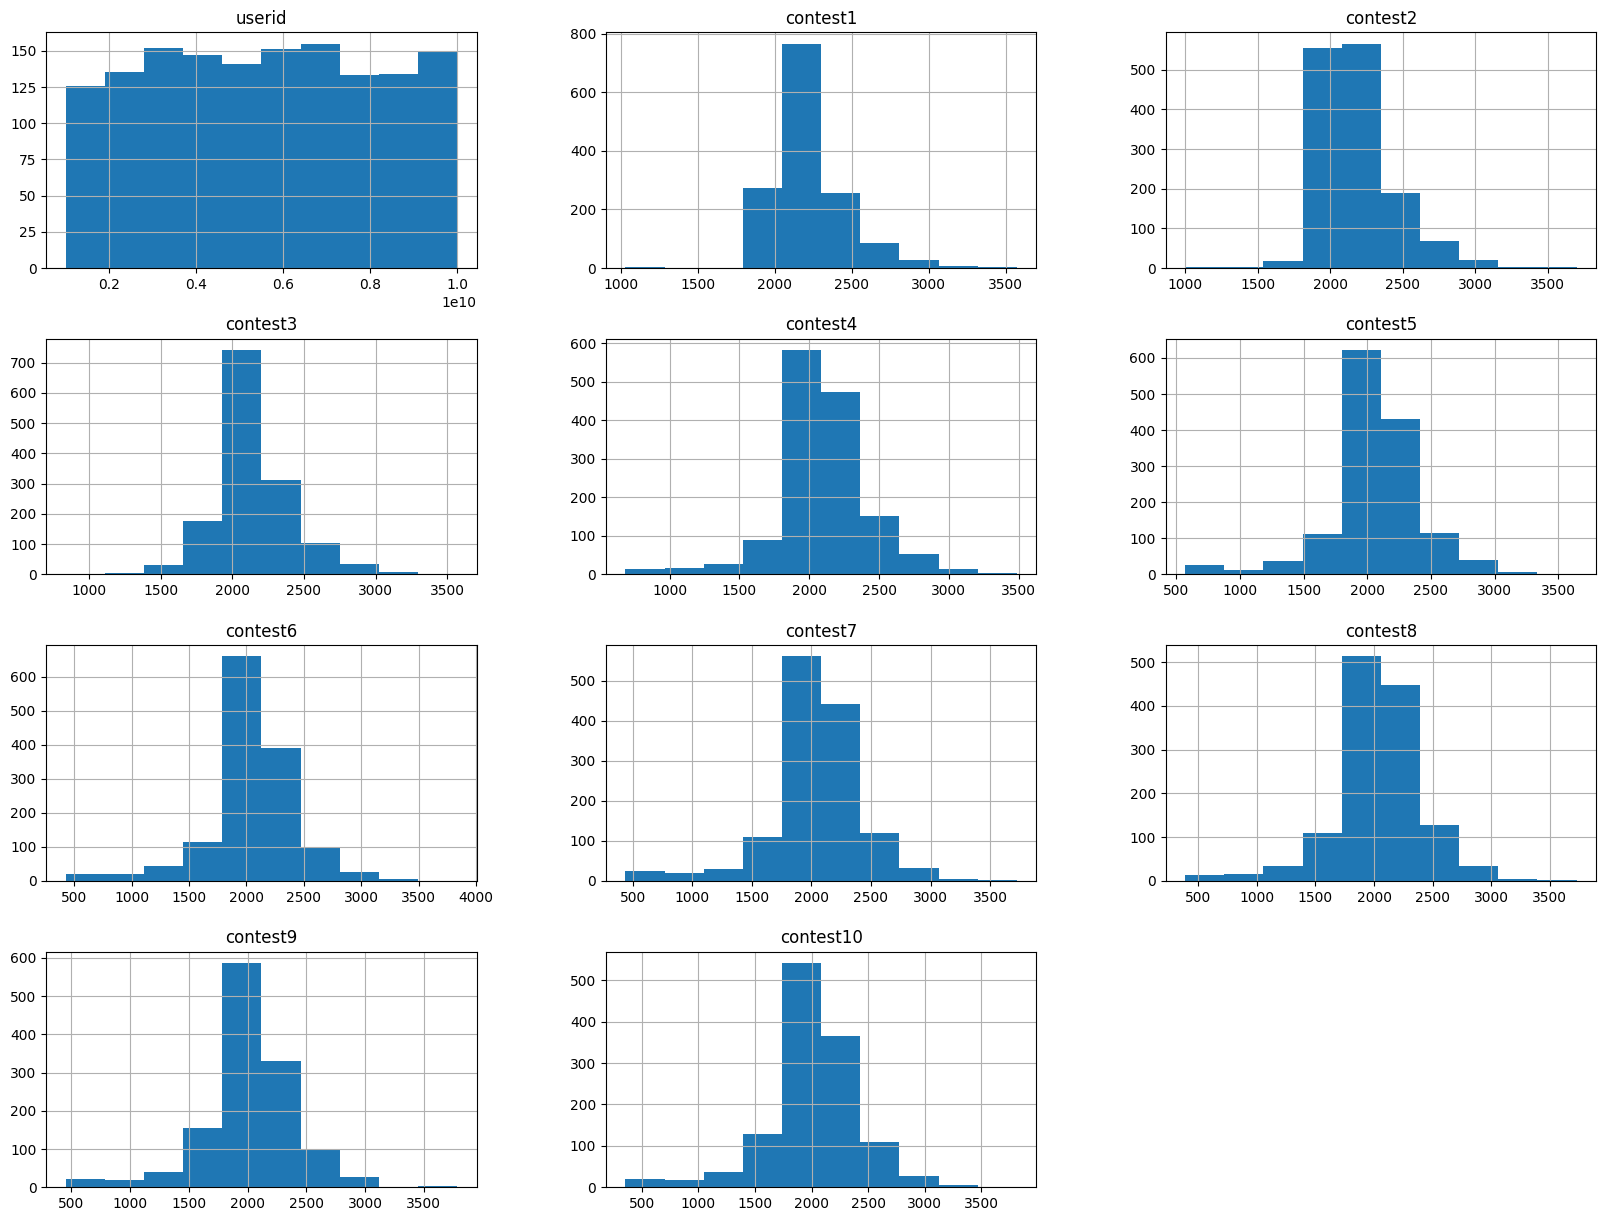

In [14]:
data.hist(figsize=(20, 15))
plt.show()